# Recording demos in LeRobot format

Exports extracted `HumanDemo`s as a LeRobotDataset v3: one episode per demo, the phone view as video, TCP/aperture as state, next-step TCP displacement + grasp flag as a (human-proxy) action, and the bowl/plate poses as per-frame constants. Then reloads it with `LeRobotDataset` to show what a consumer sees.

- `ego2robo.recorder`: `LeRobotRecorder` (schema-agnostic; reused for the sim-generated dataset)
- `ego2robo.human_dataset`: `human_features`, `HumanDemoExporter`

**Stand-in data.** The demo is the flagged synthetic-marker clip from `05_hand_tracking.ipynb` (real hand frames from a third-party GIF, synthetic markers, guessed intrinsics), exported with the QC gate overridden. It shows the format, not real data. The dataset is written to a temp dir.

In [1]:
from ego2robo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

In [2]:
import tempfile
from pathlib import Path

from lerobot.datasets.lerobot_dataset import LeRobotDataset

from ego2robo.human_dataset import (
    ACTION_NAMES,
    STATE_NAMES,
    describe_features,
    export_human_dataset,
    read_episode_vectors,
    write_episode_dashboard_video,
)
from ego2robo.recorder import SIDECAR_NAME
from ego2robo.utils.notebook import show_video
from ego2robo.utils.plotting import plot_episode_overview
from ego2robo.utils.synthetic import StandInScene

SCENE = StandInScene.from_clip_dir(ROOT / "data/raw/overview_gif/first_clip")
WORK_DIR = Path(tempfile.mkdtemp())
demo, report = SCENE.extract(SCENE.render_clip(WORK_DIR / "clip.mp4"))
print(f"{len(demo.timestamps_s)} samples; QC: {report.reasons}")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791680180.703195  403875 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791680180.713214  403875 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791680180.755203  403874 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


33 samples; QC: ['no release detected', 'grasp 0.14 m from bowl marker']


## Schema and export

Two episodes (the same demo twice, enough to show multi-episode indexing). Images are resized to 360x640 and sampled at the demo's own timestamps, nearest source frame, so every stored pixel is a real captured frame.

In [3]:
ROOT_DS = WORK_DIR / "human_dataset"

export_human_dataset(
    [demo, demo],  # the same demo twice: enough to show multi-episode indexing
    ROOT_DS,
    SCENE.intrinsics,
    task="put the bowl on the plate",
    image_size_hw=(360, 640),
    fps=20,
)
print(sorted(p.name for p in ROOT_DS.iterdir()))

Map:   0%|          | 0/33 [00:00<?, ? examples/s]

Svt[info]: -------------------------------------------
Svt[info]: SVT [version]:	SVT-AV1 Encoder Lib v3.0.0
Svt[info]: SVT [build]  :	GCC 14.2.1 20250110 (Red Hat 14.2.1-7)	 64 bit
Svt[info]: LIB Build date: Jul  3 2025 03:14:07
Svt[info]: -------------------------------------------
Svt[warn]: Preset M12 is mapped to M10.
Svt[info]: Level of Parallelism: 6
Svt[info]: Number of PPCS 161
Svt[info]: [asm level on system : up to avx2]
Svt[info]: [asm level selected : up to avx2]
Svt[info]: -------------------------------------------
Svt[info]: SVT [config]: main profile	tier (auto)	level (auto)
Svt[info]: SVT [config]: width / height / fps numerator / fps denominator 		: 640 / 360 / 20 / 1
Svt[info]: SVT [config]: bit-depth / color format 					: 8 / YUV420
Svt[info]: SVT [config]: preset / tune / pred struct 					: 10 / PSNR / random access
Svt[info]: SVT [config]: gop size / mini-gop size / key-frame type 			: 2 / 16 / key frame
Svt[info]: SVT [config]: BRC mode / rate factor 					: CRF /

Map:   0%|          | 0/33 [00:00<?, ? examples/s]

Svt[info]: -------------------------------------------
Svt[info]: SVT [version]:	SVT-AV1 Encoder Lib v3.0.0
Svt[info]: SVT [build]  :	GCC 14.2.1 20250110 (Red Hat 14.2.1-7)	 64 bit
Svt[info]: LIB Build date: Jul  3 2025 03:14:07
Svt[info]: -------------------------------------------
Svt[warn]: Preset M12 is mapped to M10.
Svt[info]: Level of Parallelism: 6
Svt[info]: Number of PPCS 161
Svt[info]: [asm level on system : up to avx2]
Svt[info]: [asm level selected : up to avx2]
Svt[info]: -------------------------------------------
Svt[info]: SVT [config]: main profile	tier (auto)	level (auto)
Svt[info]: SVT [config]: width / height / fps numerator / fps denominator 		: 640 / 360 / 20 / 1
Svt[info]: SVT [config]: bit-depth / color format 					: 8 / YUV420
Svt[info]: SVT [config]: preset / tune / pred struct 					: 10 / PSNR / random access
Svt[info]: SVT [config]: gop size / mini-gop size / key-frame type 			: 2 / 16 / key frame
Svt[info]: SVT [config]: BRC mode / rate factor 					: CRF /

['data', 'ego2robo_meta.json', 'images', 'meta', 'videos']


[mp4 @ 0x628f3a40] Starting second pass: moving the moov atom to the beginning of the file


## Reading it back

Loaded the way `lerobot-train` would, with the `pyav` video backend (the torchcodec gotcha from `CLAUDE.md`).

In [4]:
ds = LeRobotDataset("local/ego2robo_human_demos", root=ROOT_DS, video_backend="pyav")
print(f"episodes={ds.num_episodes} frames={ds.num_frames} fps={ds.fps}")
for line in describe_features(ds):
    print("  " + line)
sample = ds[5]
print("task:", sample["task"])

episodes=2 frames=66 fps=20
  observation.images.phone     video    (360, 640, 3)
  observation.state            float32  (4,)
  action                       float32  (4,)
  observation.bowl_pose        float32  (7,)
  observation.plate_pose       float32  (7,)
task: put the bowl on the plate


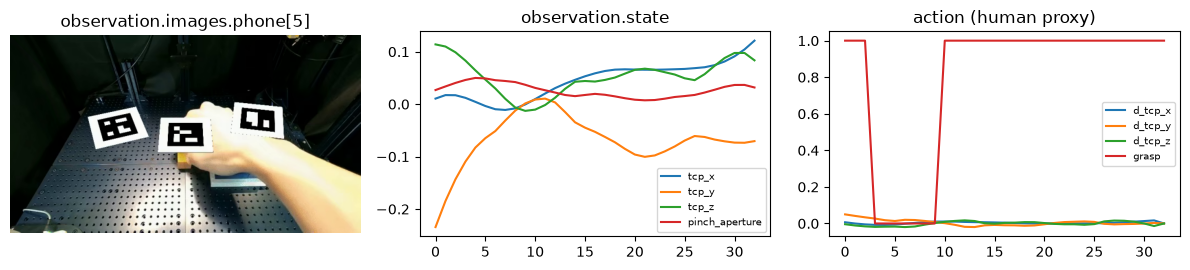

In [5]:
state, action = read_episode_vectors(ds, len(demo.timestamps_s))
plot_episode_overview(
    sample["observation.images.phone"].permute(1, 2, 0).numpy(),
    state,
    action,
    STATE_NAMES,
    ACTION_NAMES,
    image_title="observation.images.phone[5]",
)

### Synced episode video

One episode as a consumer reads it, on one clock: the stored phone frame, the `observation.state` TCP path in the table frame (grey = whole path, blue = so far, red = grasping per the `action` grasp flag, black dot = now), and below it the pinch aperture, all four `observation.state` channels and the `action` channels (`d_tcp_*` on the left axis, the 0/1 `grasp` flag dashed on the right), each with the same red time cursor.

In [6]:
episode_video = write_episode_dashboard_video(
    ds, 0, WORK_DIR / "episode_0.mp4", close_threshold_m=0.03, open_threshold_m=0.05
)
show_video(episode_video, width=960)

In [7]:
import json

meta = json.loads((ROOT_DS / SIDECAR_NAME).read_text())
print(meta["frames"])
print(meta["action_semantics"])
print({k: meta["episodes"][0][k] for k in ("source_start_time_s", "grasp_frame_idx", "release_frame_idx")})

all poses are in the table (ArUco marker) frame; pose = [x, y, z, qw, qx, qy, qz]
human proxy: next-step TCP displacement (m), grasp flag; not robot commands
{'source_start_time_s': 0.30000000000000004, 'grasp_frame_idx': 11, 'release_frame_idx': None}


## Notes

- `action` for human data is not a robot command: it is the hand's next-step TCP displacement and grasp flag. The sim-generated dataset will use the real 7-D LIBERO action through the same `LeRobotRecorder`.
- The reference `lerobot/libero` dataset is 10 fps (AV1, 256x256, state 8-D, action 7-D; read from its `meta/info.json` only), but `lerobot-eval`'s LIBERO env config runs at `fps = 20` (robosuite's control_freq). The sim dataset follows the env: 20 fps, the same rate as these human demos.
- `ego2robo_meta.json` carries what the LeRobot schema has no slot for (intrinsics at source resolution, table-frame convention, grasp/release indices, per-episode camera pose).